# Task 3: Single-node model and the Norway Wind capital cost threshold

All generators and loads are connected to the Frankfurt bus, so the transmission network no longer matters. In addition:
1. All generators are attached to Frankfurt.
2. All loads are attached to Frankfurt.
3. `p_max_pu` of Norway Wind is set to 1 for every snapshot.
4. `p_nom_min` of Manchester Wind and Frankfurt Wind is set to 0.

After that, I find the capital cost of Norway Wind at which the optimiser starts replacing Frankfurt Gas with more Norway Wind.

In [1]:
import logging, warnings
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

warnings.filterwarnings("ignore")
logging.getLogger("pypsa").setLevel(logging.ERROR)
logging.getLogger("linopy").setLevel(logging.ERROR)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
SOLVER = "highs"  # free solver, installed with: pip install highspy

In [2]:
def load_network():
    """Meshed AC-DC example, exactly as in the PyPSA documentation."""
    n = pypsa.examples.ac_dc_meshed()
    n.links.loc["Norwich Converter", "p_nom_extendable"] = False
    return n

def total_cost(n):
    return n.objective + n.objective_constant

def single_node(norway_wind_capital_cost=None):
    n = load_network()
    n.generators["bus"] = "Frankfurt"                                  # (1)
    n.loads["bus"] = "Frankfurt"                                       # (2)
    n.generators_t.p_max_pu["Norway Wind"] = 1.0                       # (3)
    n.generators.loc[["Manchester Wind", "Frankfurt Wind"], "p_nom_min"] = 0  # (4)
    if norway_wind_capital_cost is not None:
        n.generators.loc["Norway Wind", "capital_cost"] = norway_wind_capital_cost
    n.optimize(solver_name=SOLVER, log_to_console=False)
    return n

n = single_node()
print(f"Total system cost: {total_cost(n):,.0f} EUR")
print(n.generators[["capital_cost", "marginal_cost", "p_nom_min", "p_nom_opt"]].round(2))

Total system cost: 7,843,000 EUR
                 capital_cost  marginal_cost  p_nom_min  p_nom_opt
name                                                              
Manchester Wind       2793.65           0.11        0.0       0.00
Manchester Gas         196.62           4.53        0.0       0.00
Norway Wind           2184.37           0.09      100.0    3549.14
Norway Gas             158.25           5.89        0.0       0.00
Frankfurt Wind        2129.46           0.10        0.0       0.00
Frankfurt Gas          102.68           4.09        0.0     794.45


The lines and links are still in the model, but no generator or load sits on any bus other than Frankfurt, so nothing flows through them and their optimised capacities fall to zero (apart from the fixed Norwich converter, which just sits unused). They are now redundant, as the task says.

In [3]:
print("Flows on lines and links (should be zero):",
      n.lines_t.p0.abs().values.max().round(3), n.links_t.p0.abs().values.max().round(3))
print("\nDispatch [MW]:")
d = n.generators_t.p.loc[:, n.generators.p_nom_opt > 1e-3].round(1)
d["load"] = n.loads_t.p_set.sum(axis=1).round(1)
d

Flows on lines and links (should be zero): 0.0 0.0

Dispatch [MW]:


name,Norway Wind,Frankfurt Gas,load
snapshot,,,
2015-01-01 00:00:00,3167.0,-0.0,3167.0
2015-01-01 01:00:00,3549.1,431.7,3980.9
2015-01-01 02:00:00,1688.8,-0.0,1688.8
2015-01-01 03:00:00,3340.1,-0.0,3340.1
2015-01-01 04:00:00,2689.4,-0.0,2689.4
2015-01-01 05:00:00,3549.1,794.4,4343.6
2015-01-01 06:00:00,3238.8,-0.0,3238.8
2015-01-01 07:00:00,2840.0,-0.0,2840.0
2015-01-01 08:00:00,3549.1,239.1,3788.2


## 3.1 Base result

With `p_max_pu = 1`, Norway Wind behaves like a **firm, always-available resource** that runs at almost no cost (0.09 EUR/MWh). It is also the cheapest wind to build (2,184 EUR/MW). The result:

* **Norway Wind: about 3,549 MW**, which covers the base of the load in every hour.
* **Frankfurt Gas: about 794 MW**, which covers the peaks above 3,549 MW at 01:00, 05:00 and 08:00.
* Manchester Wind and Frankfurt Wind are not built, since their minimum of 100 MW has been removed.

Gas still gets built because, **per MW**, it is about 21 times cheaper to build than Norway Wind (102.7 vs 2,184 EUR/MW). For a peak that lasts only one to three hours, a cheap-to-build plant with a higher running cost beats an expensive-to-build plant with no running cost. The only thing holding gas back is the CO2 cap. Gas generation is exactly 1,465 MWh, the most the 1000 t cap allows.

## 3.2 At what capital cost does Norway Wind replace Frankfurt Gas?

**Analytical reasoning.** Sort the load from highest to lowest (a load duration curve). Gas covers the top slices. A slice of 1 MW that is needed for *h* hours costs:

* with gas: `102.677 + 4.0863 × h` EUR,
* with Norway Wind: `c_wind + 0.09 × h` EUR.

Wind takes over a slice when `c_wind < 102.677 + (4.0863 − 0.09) × h = 102.677 + 3.9963 × h`.

The gas slices last 3 hours (between 3,549 and 3,788 MW, needed at 01:00, 05:00 and 08:00), 2 hours (3,788 to 3,981 MW) and 1 hour (above 3,981 MW, only at 05:00). The 3-hour slice is replaced first:

| Gas slice | Hours | Threshold for Norway Wind capital cost |
|---|---|---|
| 3,549 to 3,788 MW | 3 | 102.677 + 3 × 3.9963 = **114.67 EUR/MW** (replacement starts) |
| 3,788 to 3,981 MW | 2 | 102.677 + 2 × 3.9963 = **110.67 EUR/MW** |
| 3,981 to 4,344 MW | 1 | 102.677 + 1 × 3.9963 = **106.67 EUR/MW** (gas fully gone) |

Above 114.67 EUR/MW, lowering the wind cost does **not** change the mix. It only lowers the CO2 shadow price, because the cap stays binding and gas stays at 794 MW. The CO2 shadow price reaches zero at exactly 114.67 EUR/MW, which is the same threshold: from that point the cap is no longer what holds gas back, because gas is now worse than wind on cost alone.

In [4]:
import numpy as np

g, w = n.generators.loc["Frankfurt Gas"], n.generators.loc["Norway Wind"]
for h in (3, 2, 1):
    print(f"{h}-hour slice: threshold = {g.capital_cost + h * (g.marginal_cost - w.marginal_cost):.3f} EUR/MW")

3-hour slice: threshold = 114.666 EUR/MW
2-hour slice: threshold = 110.670 EUR/MW
1-hour slice: threshold = 106.673 EUR/MW


**Numerical confirmation.** I sweep the Norway Wind capital cost from its original value of 2,184 EUR/MW down to 100 EUR/MW and re-run the optimisation each time.

In [5]:
costs = sorted(set(np.r_[2184.37, 2000, 1500, 1000, 500, 300, 200, 150, 130, 120,
                          np.arange(118, 104, -0.5), 114.68, 114.65, 110.69, 110.65, 106.69, 106.65]), reverse=True)
rows = []
for c in costs:
    m = single_node(c)
    rows.append({
        "norway_wind_capital_cost": c,
        "gas_capacity_MW": m.generators.p_nom_opt["Frankfurt Gas"],
        "norway_wind_MW": m.generators.p_nom_opt["Norway Wind"],
        "gas_energy_MWh": m.generators_t.p["Frankfurt Gas"].sum(),
        "co2_shadow_price": -m.global_constraints.mu["co2_limit"],
        "total_cost": total_cost(m),
    })
sweep = pd.DataFrame(rows).set_index("norway_wind_capital_cost")
pd.set_option("display.max_rows", 100)
sweep.loc[125:104].round(2)

,gas_capacity_MW,norway_wind_MW,gas_energy_MWh,co2_shadow_price,total_cost
norway_wind_capital_cost,,,,,
120.00,794.45,3549.14,1465.27,2.61,516252.92
118.00,794.45,3549.14,1465.27,1.63,509154.65
117.50,794.45,3549.14,1465.27,1.38,507380.08
117.00,794.45,3549.14,1465.27,1.14,505605.51
116.50,794.45,3549.14,1465.27,0.90,503830.94
116.00,794.45,3549.14,1465.27,0.65,502056.37
115.50,794.45,3549.14,1465.27,0.41,500281.81
115.00,794.45,3549.14,1465.27,0.16,498507.24
114.68,794.45,3549.14,1465.27,0.01,497371.52


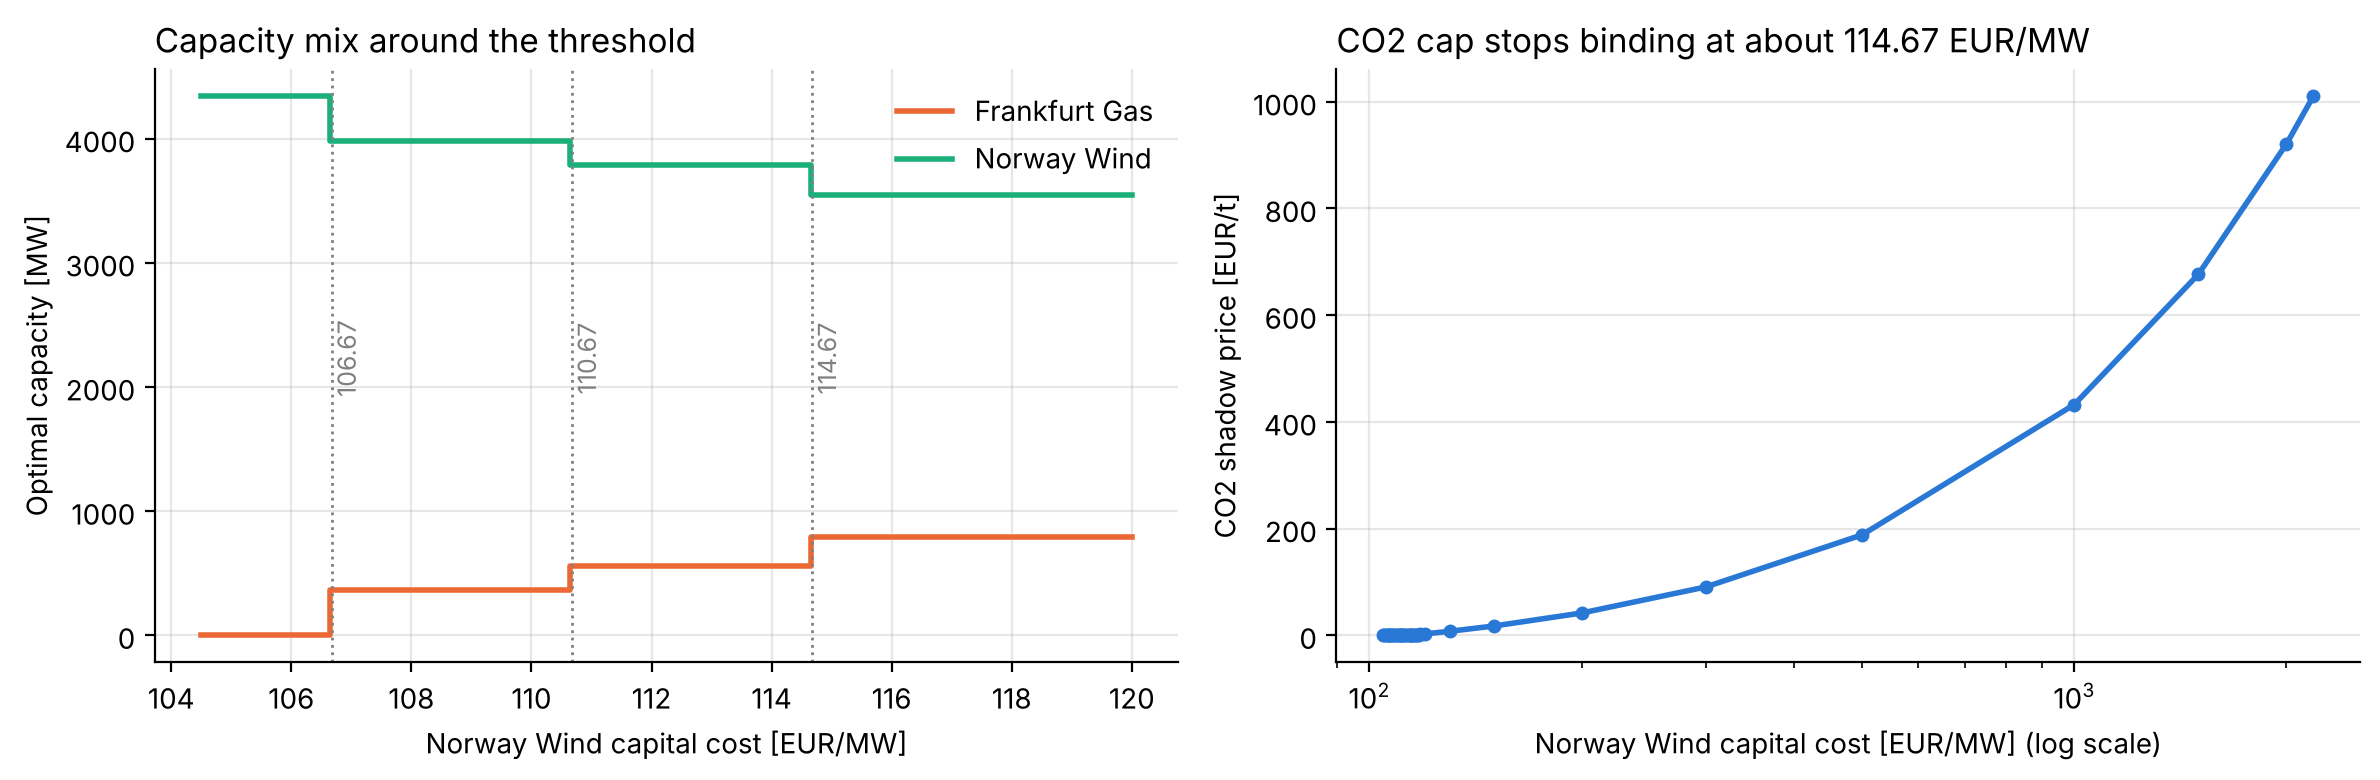

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
s = sweep.loc[sweep.index <= 125].sort_index()
ax = axes[0]
ax.step(s.index, s.gas_capacity_MW, where="pre", color="#eb6834", lw=2, label="Frankfurt Gas")
ax.step(s.index, s.norway_wind_MW, where="pre", color="#1baf7a", lw=2, label="Norway Wind")
for x in (106.67, 110.67, 114.67):
    ax.axvline(x, color="grey", ls=":", lw=1)
    ax.text(x, 2200, f" {x}", rotation=90, va="center", fontsize=9, color="grey")
ax.set_xlabel("Norway Wind capital cost [EUR/MW]"); ax.set_ylabel("Optimal capacity [MW]")
ax.set_title("Capacity mix around the threshold", loc="left")
ax.legend(frameon=False); ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
ax.plot(sweep.index, sweep.co2_shadow_price, color="#2a78d6", lw=2, marker="o", ms=4)
ax.set_xscale("log")
ax.set_xlabel("Norway Wind capital cost [EUR/MW] (log scale)"); ax.set_ylabel("CO2 shadow price [EUR/t]")
ax.set_title("CO2 cap stops binding at about 114.67 EUR/MW", loc="left")
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [7]:
for c in (114.8, 114.5, 110.5, 106.5):
    m = single_node(c)
    print(f"\nNorway Wind capital cost = {c} EUR/MW")
    print(m.generators.p_nom_opt[m.generators.p_nom_opt > 1e-3].round(2).to_string())
    print("Gas dispatch [MW]:", m.generators_t.p["Frankfurt Gas"].round(1).values)


Norway Wind capital cost = 114.8 EUR/MW
name
Norway Wind      3549.14
Frankfurt Gas     794.45
Gas dispatch [MW]: [ -0.  431.7  -0.   -0.   -0.  794.4  -0.   -0.  239.1  -0. ]



Norway Wind capital cost = 114.5 EUR/MW
name
Norway Wind      3788.24
Frankfurt Gas     555.34
Gas dispatch [MW]: [ -0.  192.6  -0.   -0.   -0.  555.3  -0.   -0.   -0.   -0. ]



Norway Wind capital cost = 110.5 EUR/MW
name
Norway Wind      3980.85
Frankfurt Gas     362.73
Gas dispatch [MW]: [ -0.   -0.   -0.   -0.   -0.  362.7  -0.   -0.   -0.   -0. ]



Norway Wind capital cost = 106.5 EUR/MW
name
Norway Wind    4343.59
Gas dispatch [MW]: [-0. -0. -0. -0. -0. -0. -0. -0. -0. -0.]


## 3.3 Answer

* The optimiser starts replacing Frankfurt Gas with Norway Wind once the **Norway Wind capital cost falls below about 114.67 EUR/MW**. At that point gas capacity drops from 794 MW to 555 MW, because gas is pushed out of the 3-hour slice.
* It replaces more at **110.67 EUR/MW** (gas falls to 363 MW and only runs at 05:00) and replaces **all** of the gas below **106.67 EUR/MW**, where Norway Wind alone (4,344 MW) covers the peak.
* The sweep confirms the analytical thresholds: the mix changes between 114.65 and 114.68, between 110.65 and 110.69, and between 106.65 and 106.69 EUR/MW. Exactly at a threshold the two options cost the same, so the LP has more than one optimal solution. That degeneracy is probably the source of the slight numerical instability mentioned in the assignment.

**Why it is so low compared with 2,184 EUR/MW.** With the CO2 cap binding, gas is not competing with wind on fuel cost. It is competing as cheap peaking capacity. Wind can only win by being about as cheap to build as a gas plant, because each extra MW of wind replaces gas capacity that runs for only one to three hours.